In [1]:
!pip install -q transformers datasets accelerate evaluate

from google.colab import drive
drive.mount('/content/drive')

import os, time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback,
)

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device:         {torch.cuda.get_device_name(0)}")
print(f"GPU memory:     {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.6 MB/s eta 0:00:00
Mounted at /content/drive
CUDA available: True
Device:         Tesla T4
GPU memory:     14.6 GB


In [2]:
DATA_DIR   = "/content/drive/MyDrive/thesis_stage2"
MODEL_NAME = "roberta-base"

df_train = pd.read_csv(f"{DATA_DIR}/therapistqa_train.csv")
df_val   = pd.read_csv(f"{DATA_DIR}/therapistqa_val.csv")
df_test  = pd.read_csv(f"{DATA_DIR}/therapistqa_test.csv")

print("Before filtering (Stage 2 splits):")
print(f"  Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")

# 3A: keep only distorted records — they're the only ones with a span
df_train = df_train[df_train["is_distorted"] == True].reset_index(drop=True)
df_val   = df_val[df_val["is_distorted"]   == True].reset_index(drop=True)
df_test  = df_test[df_test["is_distorted"] == True].reset_index(drop=True)

print("\nAfter filtering (distorted only):")
print(f"  Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")

# Sanity: distorted_part should be fully populated now
for name, df in [("train", df_train), ("val", df_val), ("test", df_test)]:
    n_missing = df["distorted_part"].isna().sum()
    assert n_missing == 0, f"{name} still has {n_missing} rows without a span"

# Build label maps — 10 classes (no "No Distortion")
classes  = sorted(df_train["dominant_distortion"].unique())
label2id = {label: idx for idx, label in enumerate(classes)}
id2label = {idx: label for label, idx in label2id.items()}

print(f"\nClasses ({len(classes)}):")
for idx, name in id2label.items():
    print(f"  {idx}: {name}")
assert "No Distortion" not in classes, "No Distortion leaked into 3A label set"

Before filtering (Stage 2 splits):
  Train: 1768, Val: 379, Test: 379

After filtering (distorted only):
  Train: 1116, Val: 239, Test: 239

Classes (10):
  0: All-or-nothing thinking
  1: Emotional Reasoning
  2: Fortune-telling
  3: Labeling
  4: Magnification
  5: Mental filter
  6: Mind Reading
  7: Overgeneralization
  8: Personalization
  9: Should statements


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

distorted_part token-length statistics (across train+val+test):
  count:  1594
  mean:   46.6
  median: 38.0
  std:    35.2
  min:    5
  max:    403

Percentiles:
  p50  38
  p75  57
  p90  85
  p95  106
  p99  185

Coverage at common max_length values:
  max_length=64    covers 80.11%   truncates 317 records
  max_length=96    covers 93.22%   truncates 108 records
  max_length=128   covers 96.80%   truncates 51 records
  max_length=160   covers 98.49%   truncates 24 records
  max_length=192   covers 99.25%   truncates 12 records
  max_length=256   covers 99.62%   truncates 6 records
  max_length=384   covers 99.94%   truncates 1 records
  max_length=512   covers 100.00%   truncates 0 records


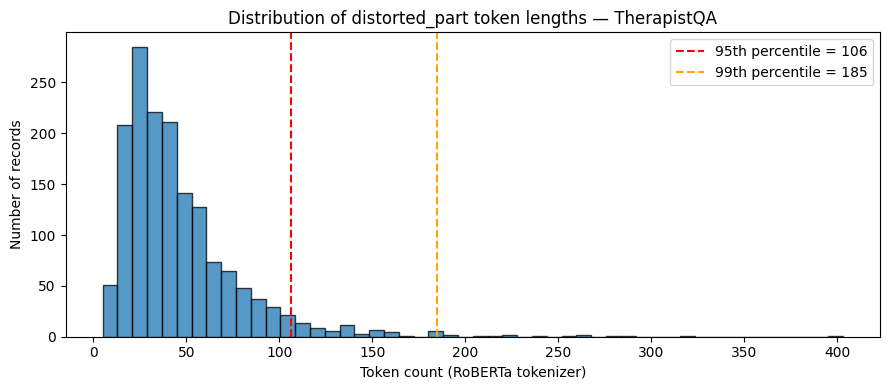

In [3]:
# Span length analysis
tokenizer_for_length = AutoTokenizer.from_pretrained(MODEL_NAME)

def token_lengths(series):
    return np.array([
        len(tokenizer_for_length(t, add_special_tokens=True)["input_ids"])
        for t in series.astype(str)
    ])

lens_train = token_lengths(df_train["distorted_part"])
lens_val   = token_lengths(df_val["distorted_part"])
lens_test  = token_lengths(df_test["distorted_part"])
lens_all   = np.concatenate([lens_train, lens_val, lens_test])

print("distorted_part token-length statistics (across train+val+test):")
print(f"  count:  {len(lens_all)}")
print(f"  mean:   {lens_all.mean():.1f}")
print(f"  median: {np.median(lens_all):.1f}")
print(f"  std:    {lens_all.std():.1f}")
print(f"  min:    {lens_all.min()}")
print(f"  max:    {lens_all.max()}")

print("\nPercentiles:")
for p in [50, 75, 90, 95, 99]:
    print(f"  p{p:<3} {np.percentile(lens_all, p):.0f}")

print("\nCoverage at common max_length values:")
for cap in [64, 96, 128, 160, 192, 256, 384, 512]:
    pct = (lens_all <= cap).mean() * 100
    truncated = (lens_all > cap).sum()
    print(f"  max_length={cap:<4}  covers {pct:5.2f}%   truncates {truncated} records")

# Histogram for the thesis appendix
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(lens_all, bins=50, edgecolor="black", alpha=0.75)
ax.axvline(np.percentile(lens_all, 95), color="red", linestyle="--",
           label=f"95th percentile = {np.percentile(lens_all, 95):.0f}")
ax.axvline(np.percentile(lens_all, 99), color="orange", linestyle="--",
           label=f"99th percentile = {np.percentile(lens_all, 99):.0f}")
ax.set_xlabel("Token count (RoBERTa tokenizer)")
ax.set_ylabel("Number of records")
ax.set_title("Distribution of distorted_part token lengths — TherapistQA")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/distorted_part_length_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
MAX_LENGTH = 192   # set based on Cell 5 — should cover >=99% of spans

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_dataset(df):
    return Dataset.from_pandas(
        df[["distorted_part", "dominant_distortion"]]
            .rename(columns={"distorted_part": "text"})
            .assign(label=lambda d: d["dominant_distortion"].map(label2id))
            [["text", "label"]],
        preserve_index=False,
    )

raw_datasets = DatasetDict({
    "train":      make_dataset(df_train),
    "validation": make_dataset(df_val),
    "test":       make_dataset(df_test),
})

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, remove_columns=["text"])

Map:   0%|          | 0/1116 [00:00<?, ? examples/s]

Map:   0%|          | 0/239 [00:00<?, ? examples/s]

Map:   0%|          | 0/239 [00:00<?, ? examples/s]

In [5]:
y_train = df_train["dominant_distortion"].map(label2id).values
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(label2id)),
    y=y_train,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda")

print("Class weights (10-way, distorted only):")
for idx, w in enumerate(class_weights):
    print(f"  {id2label[idx]:<25} {w:.3f}")

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    id2label=id2label,
    label2id=label2id,
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
        "f1_macro":    f1_score(labels, predictions, average="macro"),
    }

OUTPUT_DIR = f"{DATA_DIR}/roberta_therapistqa_3A_span_only_seed42"
FINAL_DIR  = f"{DATA_DIR}/roberta_therapistqa_3A_final"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=10,
    max_grad_norm=1.0,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    fp16=False,
    bf16=False,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=4)],
)

Class weights (10-way, distorted only):
  All-or-nothing thinking   1.617
  Emotional Reasoning       1.187
  Fortune-telling           1.105
  Labeling                  0.970
  Magnification             0.821
  Mental filter             1.298
  Mind Reading              0.668
  Overgeneralization        0.668
  Personalization           1.053
  Should statements         1.488


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [6]:
start = time.time()
train_result = trainer.train()
print(f"\nTraining finished in {(time.time() - start)/60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.307977,2.301796,0.062762,0.019907,0.021923
2,2.247316,2.029274,0.292887,0.266165,0.243604
3,1.852867,1.802101,0.351464,0.332873,0.321595
4,1.402222,1.765085,0.405858,0.394507,0.390098
5,1.026983,1.760746,0.401674,0.400095,0.398138
6,0.731177,1.786048,0.430962,0.439047,0.431897
7,0.522635,1.907696,0.405858,0.406795,0.405956
8,0.375244,1.946861,0.435146,0.432578,0.426456
9,0.279411,2.011757,0.414226,0.421621,0.412633


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.307977,2.301796,0.062762,0.019907,0.021923
2,2.247316,2.029274,0.292887,0.266165,0.243604
3,1.852867,1.802101,0.351464,0.332873,0.321595
4,1.402222,1.765085,0.405858,0.394507,0.390098
5,1.026983,1.760746,0.401674,0.400095,0.398138
6,0.731177,1.786048,0.430962,0.439047,0.431897
7,0.522635,1.907696,0.405858,0.406795,0.405956
8,0.375244,1.946861,0.435146,0.432578,0.426456
9,0.279411,2.011757,0.414226,0.421621,0.412633
10,0.226090,2.034668,0.426778,0.435222,0.426115


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training finished in 7.4 minutes


In [8]:
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Saved final model and tokenizer to {FINAL_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model and tokenizer to /content/drive/MyDrive/thesis_stage2/roberta_therapistqa_3A_final


=== Test set metrics ===
  test_loss: 1.9782
  test_accuracy: 0.3933
  test_f1_weighted: 0.3914
  test_f1_macro: 0.3650
  test_runtime: 2.3591
  test_samples_per_second: 101.3080
  test_steps_per_second: 3.3910

=== Per-category report ===
                         precision    recall  f1-score   support

All-or-nothing thinking      0.000     0.000     0.000        15
    Emotional Reasoning      0.217     0.250     0.233        20
        Fortune-telling      0.545     0.571     0.558        21
               Labeling      0.462     0.720     0.562        25
          Magnification      0.417     0.345     0.377        29
          Mental filter      0.138     0.222     0.170        18
           Mind Reading      0.684     0.361     0.473        36
     Overgeneralization      0.385     0.417     0.400        36
        Personalization      0.579     0.478     0.524        23
      Should statements      0.333     0.375     0.353        16

               accuracy                    

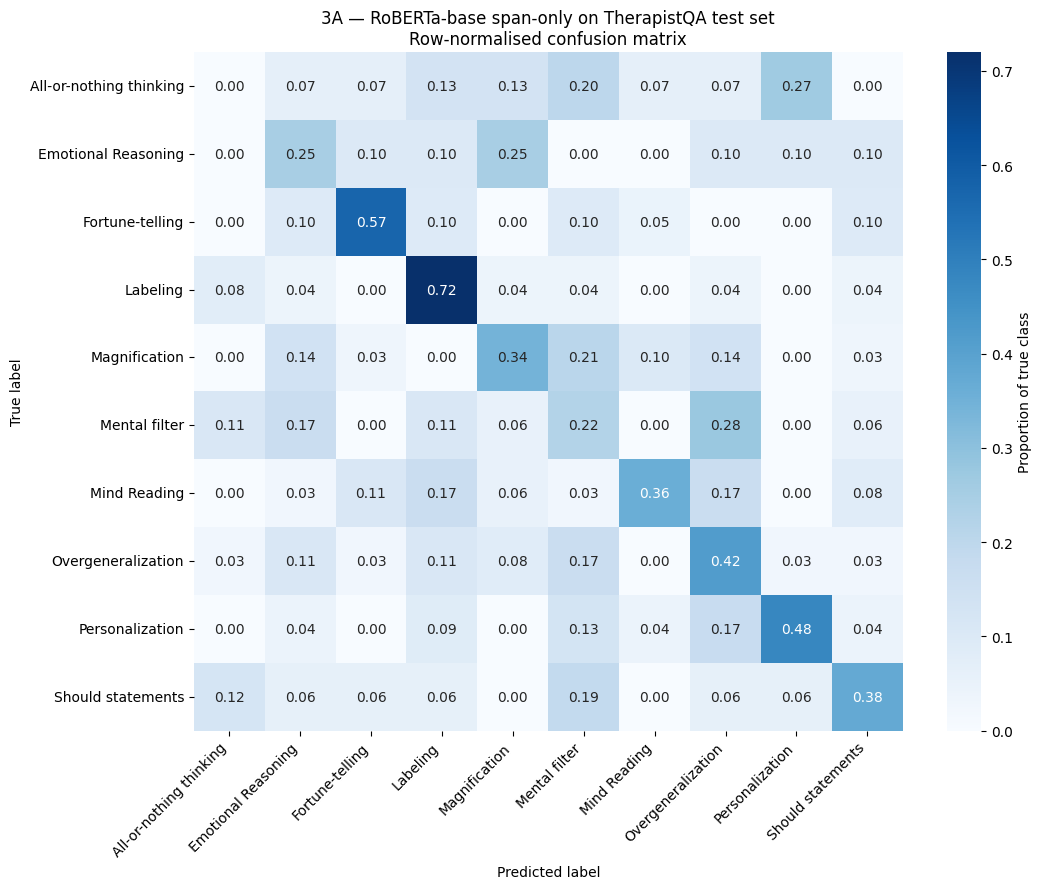

Saved confusion matrix to /content/drive/MyDrive/thesis_stage2/confusion_matrix_therapistqa_3A.png


In [9]:
test_predictions = trainer.predict(tokenized_datasets["test"])
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids

print("=== Test set metrics ===")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

print("\n=== Per-category report ===")
print(classification_report(
    y_true, y_pred,
    target_names=[id2label[i] for i in range(len(id2label))],
    digits=3,
))

# Predictions CSV (with per-class probabilities for later analysis)
predictions_df = pd.DataFrame({
    "y_true":     y_true,
    "y_pred":     y_pred,
    "true_label": [id2label[i] for i in y_true],
    "pred_label": [id2label[i] for i in y_pred],
    "text":       df_test["distorted_part"].values,
})

probs = torch.nn.functional.softmax(
    torch.tensor(test_predictions.predictions), dim=-1
).numpy()
for idx in range(len(id2label)):
    predictions_df[f"prob_{id2label[idx]}"] = probs[:, idx]

predictions_csv = f"{DATA_DIR}/roberta_therapistqa_3A_test_predictions.csv"
predictions_df.to_csv(predictions_csv, index=False)
print(f"\nSaved predictions to {predictions_csv}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
labels = [id2label[i] for i in range(len(id2label))]
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=labels, yticklabels=labels,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("3A — RoBERTa-base span-only on TherapistQA test set\nRow-normalised confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = f"{DATA_DIR}/confusion_matrix_therapistqa_3A.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved confusion matrix to {cm_path}")